# Practical 2 - Linear Regression

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [2]:
data={
    "Marketing_Budget":[10,15,20,25,30,35,40,45,50,55,60,65,70,75,80],
    "Monthly_Sales":[120,145,165,190,215,230,255,275,305,325,350,370,395,415,440]
}

In [3]:
df=pd.DataFrame(data)
df

,Marketing_Budget,Monthly_Sales
0,10,120
1,15,145
2,20,165
3,25,190
4,30,215
5,35,230
6,40,255
7,45,275
8,50,305
9,55,325


In [4]:
df.head()

,Marketing_Budget,Monthly_Sales
0,10,120
1,15,145
2,20,165
3,25,190
4,30,215


In [5]:
df.shape

(15, 2)

In [6]:
df.describe()

,Marketing_Budget,Monthly_Sales
count,15.00000,15.000000
mean,45.00000,279.666667
std,22.36068,101.848393
min,10.00000,120.000000
25%,27.50000,202.500000
50%,45.00000,275.000000
75%,62.50000,360.000000
max,80.00000,440.000000


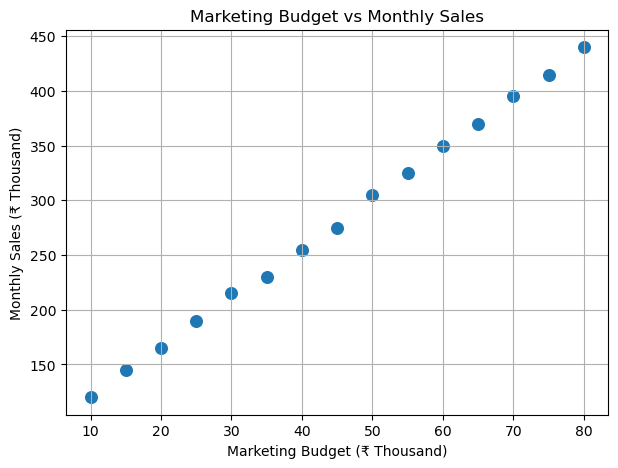

In [7]:
plt.figure(figsize=(7,5))
plt.scatter(
    df.Marketing_Budget,
    df.Monthly_Sales,
    s=70
)

plt.xlabel("Marketing Budget (₹ Thousand)")
plt.ylabel("Monthly Sales (₹ Thousand)")
plt.title("Marketing Budget vs Monthly Sales")
plt.grid()
plt.show()

In [8]:
df.dtypes

Marketing_Budget    int64
Monthly_Sales       int64
dtype: object

In [9]:
X=df[['Marketing_Budget']]
y=df.Monthly_Sales

In [10]:
X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [11]:
model=LinearRegression()
model.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [12]:
print("\nModel Parameters")
print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])
print(
    "\nEquation:"
    f"\nSales = {model.intercept_:.2f} + ({model.coef_[0]:.2f} * Marketing_Budget)"
)


Model Parameters
Intercept: 74.80640063216129
Coefficient: 4.554721453970761

Equation:
Sales = 74.81 + (4.55 * Marketing_Budget)


In [13]:
y_pred=model.predict(X_test)

In [14]:
results = pd.DataFrame({
    "Marketing_Budget": X_test["Marketing_Budget"].values,
    "Actual_Sales": y_test.values,
    "Predicted_Sales": y_pred.round(2)
})
print("\nActual vs Predicted:")
print(results)


Actual vs Predicted:
   Marketing_Budget  Actual_Sales  Predicted_Sales
0                55           325           325.32
1                65           370           370.86
2                10           120           120.35


In [15]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nModel Evaluation:")
print(f"MAE : {mae:.2f}")
print(f"MSE : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R2 : {r2:.4f}")


Model Evaluation:
MAE : 0.51
MSE : 0.32
RMSE : 0.57
R2 : 1.0000


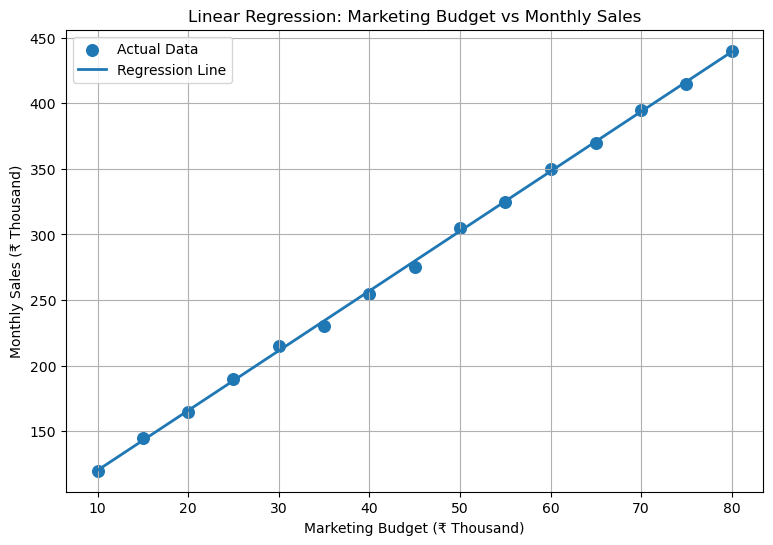

In [16]:
plt.figure(figsize=(9, 6))
plt.scatter(
    X,
    y,
    s=70,
    label="Actual Data"
)
plt.plot(
    X,
    model.predict(X),
    linewidth=2,
    label="Regression Line"
)
plt.xlabel("Marketing Budget (₹ Thousand)")
plt.ylabel("Monthly Sales (₹ Thousand)")
plt.title("Linear Regression: Marketing Budget vs Monthly Sales")
plt.legend()
plt.grid(True)
plt.show()

In [21]:
budgets = pd.DataFrame({
    "Marketing_Budget": [20, 40, 60, 80, 100]
})
predicted = model.predict(budgets)
scenario_table = pd.DataFrame({
    "Marketing_Budget_₹000": budgets["Marketing_Budget"],
    "Predicted_Sales_₹000": predicted.round(2)
})
print("\nMarketing Budget Scenarios:")
print(scenario_table)


Marketing Budget Scenarios:
   Marketing_Budget_₹000  Predicted_Sales_₹000
0                     20                165.90
1                     40                257.00
2                     60                348.09
3                     80                439.18
4                    100                530.28


# Question: 

1. The marketing manager has a budget of ₹90,000 for next month.
Using your trained model, estimate the expected sales.

2. Then compare budgets of ₹60,000, ₹80,000, ₹90,000 and ₹100,000 and
recommend a budget. 

3. Explain why your recommendation should not be
based on predicted sales alone.

In [19]:
new_budget = pd.DataFrame({
    "Marketing_Budget": [90]
})
predicted_sales = model.predict(new_budget)
print(f"\nPrediction for ₹90,000 Marketing Budget: \nExpected Sales = ₹{predicted_sales[0]:.2f} thousand")


Prediction for ₹90,000 Marketing Budget: 
Expected Sales = ₹484.73 thousand


### **Model equation:**

Sales = 74.81 + 4.55 * Marketing Budget


### 1. Expected sales for ₹90,000
Sales = 74.81 + (4.55 * 90) ≈ **₹484.73 thousand**

Therefore the expected sales are approximately **₹4,84,730**.

### 2. Budget comparison

| Marketing Budget | Predicted Sales |
| ---------------: | --------------: |
|          ₹60,000 |       ₹3,48,090 |
|          ₹80,000 |       ₹4,39,180 |
|      **₹90,000** |   **₹4,84,730** |
|        ₹1,00,000 |       ₹5,30,280 |

### 3. Recommendation

I recommend a marketing budget of ₹80,000. The model predicts sales of approximately ₹4,39,180 at this budget, compared with ₹3,48,090 at ₹60,000. 

While higher budgets of ₹90,000 and ₹100,000 produce higher predicted sales, they also require greater marketing expenditure. Therefore, the final decision should consider profit, ROI, customer demand, and the possibility of diminishing returns rather than predicted sales alone.